In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from collections import Counter

# Load dataset
df = pd.read_csv("fakenews.csv")

# Load English language model
nlp = spacy.load("en_core_web_sm")

In [2]:
# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Display first five rows
print(df[["label", "text"]].head())

print("Total articles:", len(df))

  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...
Total articles: 2212


In [3]:

# Extract noun phrases from each article
noun_phrase_records = []

for index, row in df.iterrows():
    doc = nlp(row["text"])

    for chunk in doc.noun_chunks:
        noun_phrase_records.append({
            "news_id": row["news_id"],
            "label": row["label"],
            "noun_phrase": chunk.text.lower().strip()
        })

# Convert results into a DataFrame
noun_phrases_df = pd.DataFrame(noun_phrase_records)

# Display first 20 noun phrases
print("Common Noun Phrase Examples:")
print(noun_phrases_df.head(11))


Common Noun Phrase Examples:
    news_id label                 noun_phrase
0         1  Real              global economy
1         1  Real                   recession
2         1  Real          the prime minister
3         1  Real   the inauguration ceremony
4         1  Real             the chief guest
5         2  Real                  earthquake
6         2  Real                  chittagong
7         2  Real                       panic
8         2  Real    an official announcement
9         3  Fake                breakthrough
10        3  Fake  bangladesh's tech industry


In [4]:
# Count noun phrase frequency separately for each label
noun_phrase_frequency = noun_phrases_df.groupby(
    ["label", "noun_phrase"]
).size().reset_index(name="frequency")

# Display the 10 most common noun phrases in each category
for label in noun_phrase_frequency["label"].unique():
    print(f"\nTop 10 Noun Phrases in {label} News:")

    top_phrases = (
        noun_phrase_frequency[
            noun_phrase_frequency["label"] == label
        ]
        .sort_values(by="frequency", ascending=False)
        .head(10)
    )

    print(top_phrases)


Top 10 Noun Phrases in Fake News:
   label                              noun_phrase  frequency
32  Fake                                       it        220
26  Fake                                  experts        201
9   Fake                    bangladeshi astronaut        135
40  Fake                                    photo        135
48  Fake                         the authenticity        129
53  Fake                             the incident        129
72  Fake                                     this        123
1   Fake  a significant technological advancement        123
50  Fake                                 the city        120
74  Fake                            various parts        120

Top 10 Noun Phrases in Real News:
    label         noun_phrase  frequency
107  Real                  it        212
101  Real             experts        184
79   Real          bangladesh        141
120  Real        social media        130
113  Real                noon        130
135  Real    

In [6]:

# Extract verbs from each article
verb_records = []

for index, row in df.iterrows():
    doc = nlp(row["text"])

    for token in doc:
        if token.pos_ in ["VERB", "AUX"]:
            verb_records.append({
                "news_id": row["news_id"],
                "label": row["label"],
                "verb": token.lemma_.lower()
            })

# Convert results into a DataFrame
verbs_df = pd.DataFrame(verb_records)

# Display the first 20 extracted verbs
print("Extracted Verb Patterns:")
print(verbs_df.head(20))


Extracted Verb Patterns:
    news_id label    verb
0         1  Real    face
1         1  Real  attend
2         2  Real     hit
3         2  Real  spread
4         2  Real   state
5         2  Real    will
6         2  Real      be
7         2  Real    make
8         3  Fake    have
9         3  Fake   visit
10        4  Fake  worsen
11        4  Fake  attend
12        5  Real   spark
13        5  Real    fear
14        5  Real   state
15        5  Real    will
16        5  Real      be
17        5  Real    make
18        6  Fake     hit
19        6  Fake  spread


In [7]:
# Calculate verb frequency for each news label
verb_frequency = verbs_df.groupby(
    ["label", "verb"]
).size().reset_index(name="frequency")

# Display the 10 most common verbs in each category
for label in verb_frequency["label"].unique():
    print(f"\nTop 10 Verbs in {label} News:")

    top_verbs = (
        verb_frequency[verb_frequency["label"] == label]
        .sort_values(by="frequency", ascending=False)
        .head(10)
    )


    print(top_verbs)


Top 10 Verbs in Fake News:
   label         verb  frequency
4   Fake           be        691
13  Fake         have        185
8   Fake      capture        135
20  Fake       remain        129
5   Fake      believe        123
17  Fake  investigate        120
21  Fake       report        120
7   Fake          can        117
14  Fake         help        117
3   Fake        avoid        117

Top 10 Verbs in Real News:
   label     verb  frequency
35  Real       be        613
44  Real     have        243
59  Real      win        141
43  Real       go        130
57  Real    visit        122
40  Real    claim        121
60  Real  witness        121
46  Real      hit        120
61  Real   worsen        113
49  Real   launch        113


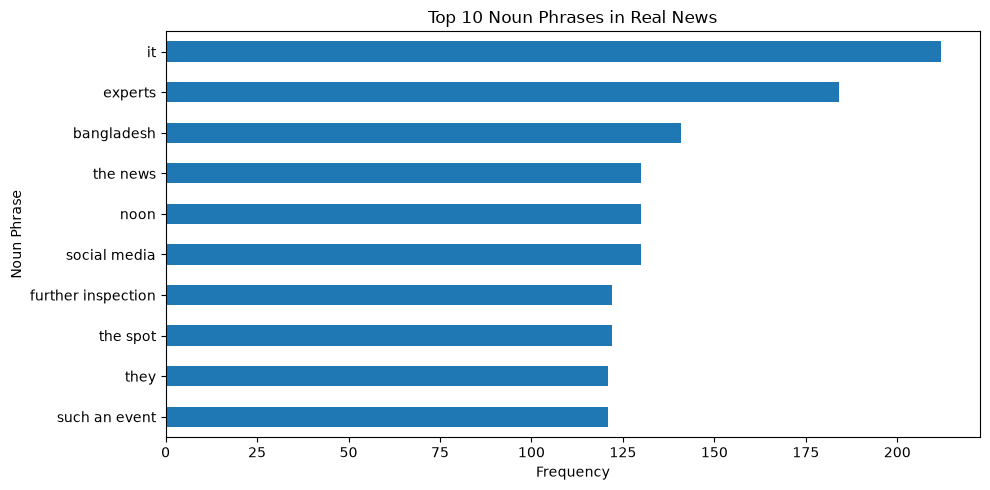

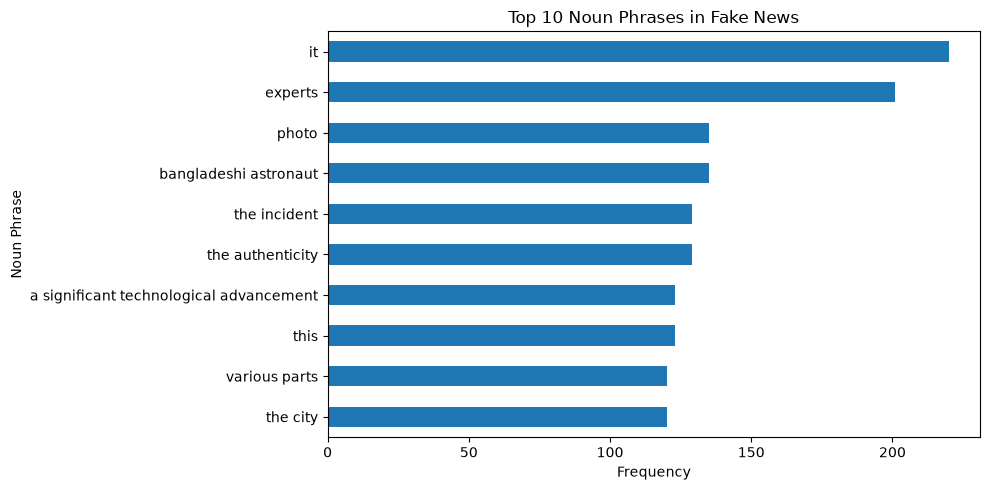

In [8]:

#Top noun phrases in Real and Fake news
for label in noun_phrases_df["label"].unique():
    top_phrases = (
        noun_phrases_df[noun_phrases_df["label"] == label]
        ["noun_phrase"]
        .value_counts()
        .head(10)
    )

    plt.figure(figsize=(10, 5))
    top_phrases.sort_values().plot(kind="barh")

    plt.title(f"Top 10 Noun Phrases in {label} News")
    plt.xlabel("Frequency")
    plt.ylabel("Noun Phrase")
    plt.tight_layout()
    plt.savefig(f"T14_top_noun_phrases_{label}.png")
    plt.show()


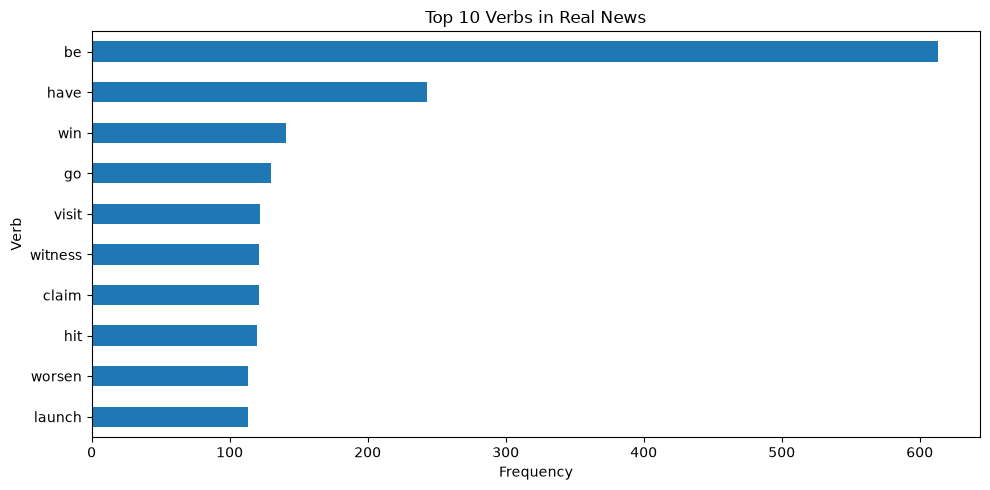

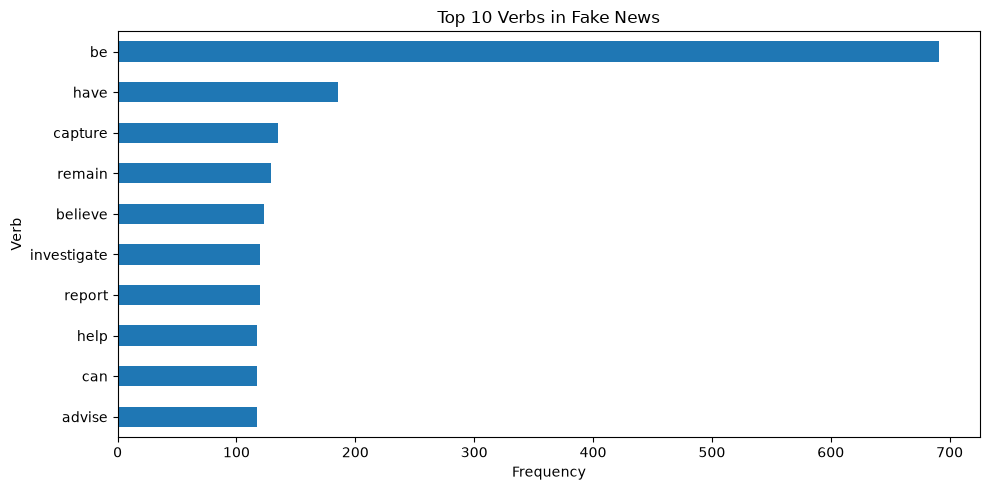

In [9]:

# Top verbs in Real and Fake news
for label in verbs_df["label"].unique():
    top_verbs = (
        verbs_df[verbs_df["label"] == label]["verb"]
        .value_counts()
        .head(10)
    )

    plt.figure(figsize=(10, 5))
    top_verbs.sort_values().plot(kind="barh")

    plt.title(f"Top 10 Verbs in {label} News")
    plt.xlabel("Frequency")
    plt.ylabel("Verb")
    plt.tight_layout()
    plt.savefig(f"T14_top_verbs_{label}.png")
    plt.show()

In [10]:
# Save extracted noun phrases
noun_phrases_df.to_csv(
    "T14_noun_phrases.csv",
    index=False
)

# Save noun phrase frequency
noun_phrase_frequency.to_csv(
    "T14_noun_phrase_frequency.csv",
    index=False
)

# Save extracted verbs
verbs_df.to_csv(
    "T14_extracted_verbs.csv",
    index=False
)

# Save verb frequency
verb_frequency.to_csv(
    "T14_verb_frequency.csv",
    index=False
)

print("Task 14 completed successfully!")

print("\nFiles saved:")
print("1. T14_noun_phrases.csv")
print("2. T14_noun_phrase_frequency.csv")
print("3. T14_extracted_verbs.csv")
print("4. T14_verb_frequency.csv")

Task 14 completed successfully!

Files saved:
1. T14_noun_phrases.csv
2. T14_noun_phrase_frequency.csv
3. T14_extracted_verbs.csv
4. T14_verb_frequency.csv
